# Experiment 2 · Single-target trials from a random start

**Date:** 2026-11-07 · **Agent:** `baseline_s1` · **Status:** observation (1 seed, 10 trials)

## Question
In training, every trial starts at x = 0. But the agent also reaches *from* targets in
multi-target trials (T1 → T2), so in principle it can reach from anywhere. **Can it start a
reach from a position other than the trained start, after holding there?**

## Design
- 10 trials, one target each, preview H = 1.
- **Start position random**, uniform in [−0.9, 0.9] (the region targets occupy in training).
- Target position random from the task distribution, at least 0.15 from the start.
- Go cue random (0.25–1.0 s hold), as in training.
- The hold rule is applied relative to the new start: the hold penalty is −20(x − x₀)² and
  moving more than 0.15 from x₀ before the go cue is a false start.
  *This is a probe-only change to the environment* (`spec["start_x"]`); training always
  starts at x₀ = 0.
- Noiseless plant, mean action.

In [1]:
from exp_tools import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Video, display
from single_target_video import make_video, outcome

use_style()
pd.set_option("display.precision", 3)

In [2]:
out, traj, infos = make_video(RUNS / "baseline_s1", trials=10, seed=0, start_range=0.9,
                              fmt="mp4", name="exp02_random_start")
print(f"video: {out}")
display(Video(rel(out), embed=False, width=820))

video: /Users/aghavamp/Desktop/Projects/SeqHorizon_basic/1D/runs/baseline_s1/videos/exp02_random_start.mp4


In [3]:
tbl = pd.DataFrame([{
    "trial": i + 1, "start": d["start"], "target": d["target"],
    "distance": abs(d["target"] - d["start"]), "hold_ms": d["hold_ms"], "RT_ms": d["rt_ms"],
    "MT_ms": d["mt_ms"], "outcome": outcome(d)} for i, d in enumerate(infos)])
tbl

,trial,start,target,distance,hold_ms,RT_ms,MT_ms,outcome
0,1,0.247,0.776,0.529,580.0,20.0,480.0,ok
1,2,-0.414,-0.827,0.413,860.0,40.0,560.0,ok
2,3,-0.826,0.418,1.244,540.0,NaN,NaN,FALSE START
3,4,-0.870,0.206,1.076,260.0,0.0,560.0,ok
4,5,0.564,-0.849,1.413,940.0,NaN,NaN,FALSE START
5,6,0.743,0.395,0.348,960.0,NaN,NaN,FALSE START
6,7,0.192,-0.871,1.063,260.0,0.0,820.0,ok
7,8,0.413,-0.781,1.194,700.0,0.0,800.0,ok
8,9,0.079,0.614,0.536,880.0,20.0,440.0,ok
9,10,0.783,-0.780,1.563,840.0,NaN,NaN,FALSE START


## What the mass does during the hold

Position relative to the start, during the hold only. The question is which way it drifts: towards the target, or towards the centre of the workspace (x = 0). The two point the same way unless the target lies further out than the start (marked *outward*).

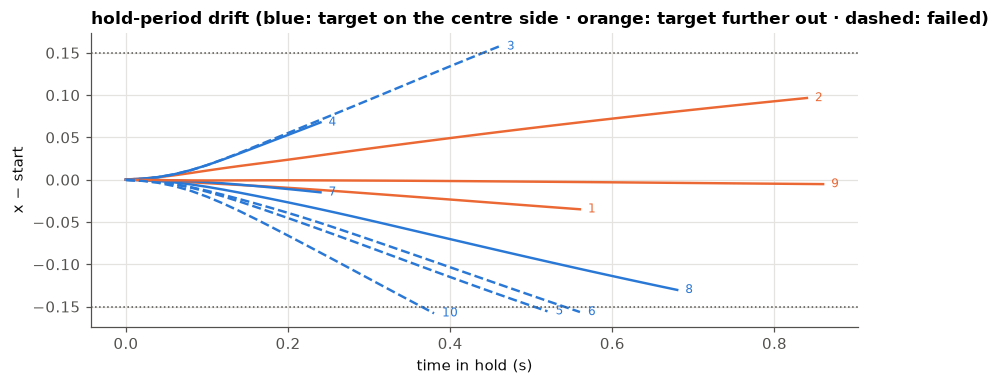

,trial,start,target,side,drift direction,v at 0.1 s,outcome
0,1,0.247,0.776,outward,towards centre,-0.052,ok
1,2,-0.414,-0.827,outward,towards centre,0.142,ok
2,3,-0.826,0.418,inward,towards centre,0.302,FALSE START
3,4,-0.870,0.206,inward,towards centre,0.295,ok
4,5,0.564,-0.849,inward,towards centre,-0.243,FALSE START
5,6,0.743,0.395,inward,towards centre,-0.214,FALSE START
6,7,0.192,-0.871,inward,towards centre,-0.057,ok
7,8,0.413,-0.781,inward,towards centre,-0.145,ok
8,9,0.079,0.614,outward,towards centre,-0.002,ok
9,10,0.783,-0.780,inward,towards centre,-0.347,FALSE START


In [4]:
dt = traj["dt"]
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, d in enumerate(infos):
    n = min(d["go"], d["T"])
    t = np.arange(n) * dt
    side = target_side(d["start"], d["target"])
    style = dict(color=ORANGE if side == "outward" else BLUE,
                 ls="-" if d["success"] else "--")
    ax.plot(t, traj["x"][:n, i] - d["start"], lw=1.6, **style)
    ax.text(t[-1] + 0.01, traj["x"][n - 1, i] - d["start"], f"{i+1}", fontsize=8,
            va="center", color=style["color"])
ax.axhline(0.15, color=INK_SOFT, ls=":", lw=1); ax.axhline(-0.15, color=INK_SOFT, ls=":", lw=1)
ax.set_xlabel("time in hold (s)"); ax.set_ylabel("x − start")
ax.set_title("hold-period drift (blue: target on the centre side · orange: target further out · dashed: failed)")
plt.tight_layout(); plt.show()

pd.DataFrame([{"trial": i + 1, "start": d["start"], "target": d["target"],
               "side": target_side(d["start"], d["target"]),
               "drift direction": "towards centre" if np.sign(traj["v"][5, i]) == -np.sign(d["start"]) else "away from centre",
               "v at 0.1 s": traj["v"][5, i], "outcome": outcome(d)} for i, d in enumerate(infos)])

## Conclusion

**The reach generalises; the hold does not.**

- **Reach:** every trial that reached the go cue hit its target (6/6), including reaches
  longer than any the agent makes from the centre in training (1.06, 1.08, 1.19 against a
  trained maximum of 0.9 from x = 0). The kinematics look like Experiment 1: a near-maximal
  push on the go step, then braking (MT 440–820 ms). This fits the idea that the reach is
  computed relative to the current position, which the agent practises in T1 → T2 movements.
- **Hold:** 4/10 trials were false starts, all from starts at least 0.56 from the centre with
  holds of at least 540 ms. In **every** trial the mass drifted towards the centre during the
  hold, including the three where the target lay further out (trials 1, 2 and 9, the last one
  barely moving), where that meant drifting *away* from the target. Trials with a short hold
  escape (trial 4: 260 ms from −0.87).
- **Framing:** the "failure" is against a hold rule the agent never saw. The probe moves the
  hold anchor to x₀, but in training the anchor was always x = 0, so the agent had no way to
  learn "stay where you started" as different from "stay at the centre".

*Limits: one seed, 10 trials, only 3 discriminating (outward) trials. Experiment 3 tests the
centre-pull explanation systematically on all 8 seeds.*